In [60]:
# 修改波特率，上电默认 5M
import serial
import sys

# -----------------------------
# 配置参数
# -----------------------------
SERIAL_PORT = "COM4" 
BAUDRATE = 5_000_000           # 默认波特率

# -----------------------------
# 波特率指令表（cmd -> baud）
# -----------------------------
UART_BAUD_TABLE = {
    0x11: 2_000_000,  # UBM11
    0x22: 2_500_000,  # UBM22
    0x33: 3_000_000,  # UBM33
    0x44: 4_000_000,  # UBM44
    0x55: 5_000_000,  # UBM55
    0x66: 6_000_000,  # UBM66
    0x77: 7_000_000,  # UBM77
    0x88: 8_000_000,
    0xAA: 5_000_000,
    0xBB: 10_000_000,
    0xCC: 921600,
}
current_baudrate = BAUDRATE

def send_baud_cmd(port, baudrate, cmd):
    global current_baudrate

    if cmd not in UART_BAUD_TABLE:
        print(f"Invalid baud command: 0x{cmd:02X}")
        return

    target_baud = UART_BAUD_TABLE[cmd]

    try:
        with serial.Serial(port, baudrate, timeout=1) as ser:
            ser.write(bytes([cmd]))
            print(
                f"Sent baud command 0x{cmd:02X}, "
                f"switching to {target_baud} baud."
            )
        current_baudrate = target_baud

    except serial.SerialException as e:
        print(f"Serial error: {e}")
        sys.exit(1)

send_baud_cmd(
    SERIAL_PORT,
    current_baudrate,
    0xAA
)

print(f"Current baudrate = {current_baudrate}")

Sent baud command 0xAA, switching to 5000000 baud.
Current baudrate = 5000000


In [8]:
# =============================
# ADC / VTEMP 温度计算
# =============================
import numpy as np

RUP = 10_000.0
R0  = 10_000.0
T0  = 298.15
B   = 3435.0

def adc_to_rntc(adc):
    adc = float(adc)
    if adc <= 0 or adc >= 4095:
        return np.nan
    return RUP * adc / (4095.0 - adc)

def rntc_to_temp_c(r):
    if r <= 0 or np.isnan(r):
        return np.nan
    inv_T = 1.0 / T0 + np.log(r / R0) / B
    return 1.0 / inv_T - 273.15

def adc_to_temp_c(adc):
    return rntc_to_temp_c(adc_to_rntc(adc))

def vtemp_to_fpa_temp_c(vtemp_mean):
    return 25.0 + (vtemp_mean - 8192.0) / 70.0


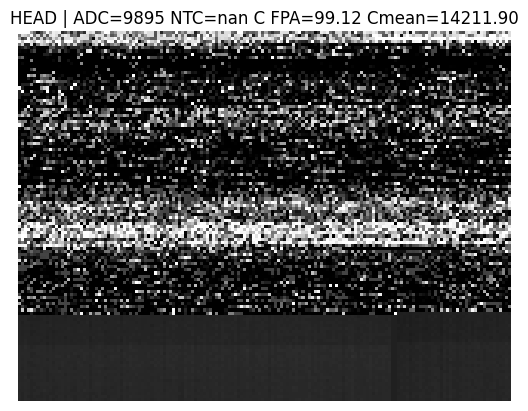

SerialException: GetOverlappedResult failed (PermissionError(13, '拒绝访问。', None, 5))

In [77]:
# 原始数据捕获脚本

import serial
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import clear_output
import os
from datetime import datetime


class ImagePacketDecoder:
    """
    RAW16 UART 图像包解析器（支持行扩展 + ADC）

    UART 包格式:
        FF FF +
        H * (W + 2) * u16   (图像 + 行扩展, BE) +
        1 * u16            (ADC, BE)

    输出:
        img_all : (H, W + 2) u16
        adc     : u16
    """

    def __init__(self, width, height, calib_file=None):
        self.width = width
        self.height = height

        self.line_words = self.width + 2
        self.total_words = self.height * self.line_words + 1
        self.packet_size = 2 + self.total_words * 2

        self.calib = None
        if calib_file is not None:
            self._load_calibration(calib_file)

    def _load_calibration(self, calib_file):
        calib = np.load(calib_file)
        if calib.shape != (self.height, self.width):
            raise ValueError("Calibration shape mismatch")
        self.calib = calib.astype(np.int32)

    @staticmethod
    def gray_to_binary(img):
        # 直通，保留接口
        return img

    def feed_packet(self, packet):
        if len(packet) != self.packet_size:
            return None
        if packet[0] != 0xFF or packet[1] != 0xFF:
            return None

        buf8 = np.frombuffer(packet[2:], dtype=np.uint8)

        raw16 = (buf8[0::2].astype(np.uint16) << 8) | \
                buf8[1::2].astype(np.uint16)

        adc_raw = raw16[-1]
        raw16_main = raw16[:-1]

        raw16_all = raw16_main.reshape(
            (self.height, self.line_words)
        )

        raw_img = raw16_all[:, :self.width]
        raw_ext = raw16_all[:, self.width:]

        img_bin = self.gray_to_binary(raw_img).astype(np.int32)
        if self.calib is not None:
            img_bin -= self.calib
            img_bin = np.clip(img_bin, 0, 65535)

        img_all = np.concatenate(
            [img_bin.astype(np.uint16), raw_ext.astype(np.uint16)],
            axis=1
        )

        return img_all, np.uint16(adc_raw)

def run_uart_capture(port, baud, width, height, calib_file=None):

    folder = datetime.now().strftime("capture_%Y%m%d_%H%M%S")
    folder = os.path.join("sensor_data_backup", folder)
    os.makedirs(folder, exist_ok=True)

    npy_path = os.path.join(folder, "frames.npy")

    frame_dtype = np.dtype([
        ("img", np.uint16, (height, width + 2)),
        ("adc", np.uint16),
    ])

    frames = []

    decoder = ImagePacketDecoder(width, height, calib_file)
    buf = bytearray()

    # adc!=0 作为组首帧
    head_frame = None

    try:
        with serial.Serial(port, baud, timeout=0.01) as ser:
            print("Receiving frames (adc!=0 as head, Ctrl+C to stop)")

            while True:
                buf.extend(ser.read(4096))

                while True:
                    idx = buf.find(b'\xFF\xFF')
                    if idx < 0:
                        buf = buf[-1:]
                        break

                    if len(buf) - idx < decoder.packet_size:
                        buf = buf[idx:]
                        break

                    packet = buf[idx:idx + decoder.packet_size]
                    buf = buf[idx + decoder.packet_size:]

                    result = decoder.feed_packet(packet)
                    if result is None:
                        continue

                    img_all, adc = result

                    # ===== 组首帧：adc != 0 =====
                    if adc != 0:
                        head_frame = np.zeros((), dtype=frame_dtype)
                        head_frame["img"] = img_all
                        head_frame["adc"] = adc

                        clear_output(wait=True)
                        # ===== VTEMP 当前帧平均 =====
                        vtemp = img_all[:, width:width+2].astype(np.float64)
                        vtemp_mean = np.mean(vtemp)
                        temp_fpa_c = vtemp_to_fpa_temp_c(vtemp_mean)

                        # ===== ADC 温度 =====
                        temp_adc_c = adc_to_temp_c(adc)
                        binmean = np.mean(img_all[:, :width])

                        clear_output(wait=True)
                        plt.imshow(img_all[:, :width], cmap="gray")

                        title = (
                            f"HEAD | ADC={int(adc)} "
                            f"NTC={temp_adc_c:.2f} C "
                            f"FPA={temp_fpa_c:.2f} C"
                            f"mean={binmean:.2f}"
                        )
                        plt.title(title)

                        plt.axis("off")
                        plt.show()
                        continue

                    # ===== 组尾帧：adc == 0 =====
                    if adc == 0 and head_frame is not None:
                        tail_frame = np.zeros((), dtype=frame_dtype)
                        tail_frame["img"] = img_all
                        tail_frame["adc"] = adc

                        frames.append(head_frame)
                        frames.append(tail_frame)

                        print(
                            f"Saved group #{len(frames)//2}, "
                            f"total frames={len(frames)}"
                        )

                        head_frame = None

                        clear_output(wait=True)
                        vtemp = img_all[:, width:width+2].astype(np.float64)
                        vtemp_mean = np.mean(vtemp)
                        temp_fpa_c = vtemp_to_fpa_temp_c(vtemp_mean)

                        clear_output(wait=True)
                        plt.imshow(img_all[:, :width], cmap="gray")
                        binmean = np.mean(img_all[:, :width])

                        title = (
                            f"TAIL | ADC=0 "
                            f"FPA={temp_fpa_c:.2f} C"
                            f"mean={binmean:.2f}"
                            "---------------------------"
                        )
                        plt.title(title)

                        plt.axis("off")
                        plt.show()

    except KeyboardInterrupt:
        print("Stopped by user")

    frames_np = np.array(frames, dtype=frame_dtype)
    np.save(npy_path, frames_np)
    print(f"Saved {len(frames)//2} groups to {npy_path}")
    return folder, npy_path

import time
ltime = time.time()
frames_folder, frames_path = run_uart_capture(
    port="COM30",
    baud=5_000_000,
    width=160,
    height=120,
    calib_file=None,
)
print(time.time()- ltime)

Split finished:
  black frames   : (205, 120, 162)
  shutter frames : (205, 120, 162)
  adc array      : (205,)
black frame average:
  frames     : 205
  mean(min)  : 7012.529
  mean(max)  : 7899.841
  mean(avg)  : 7490.516
  saved to   : sensor_data_backup\capture_20260205_180608\black_avg.npy, sensor_data_backup\capture_20260205_180608\black_avg.txt

shutter frame average:
  frames     : 205
  mean(min)  : 8299.828
  mean(max)  : 8562.676
  mean(avg)  : 8503.941
  saved to   : sensor_data_backup\capture_20260205_180608\shutter_avg.npy, sensor_data_backup\capture_20260205_180608\shutter_avg.txt



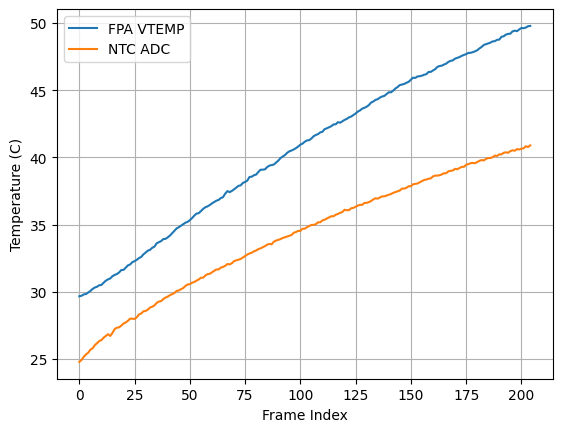

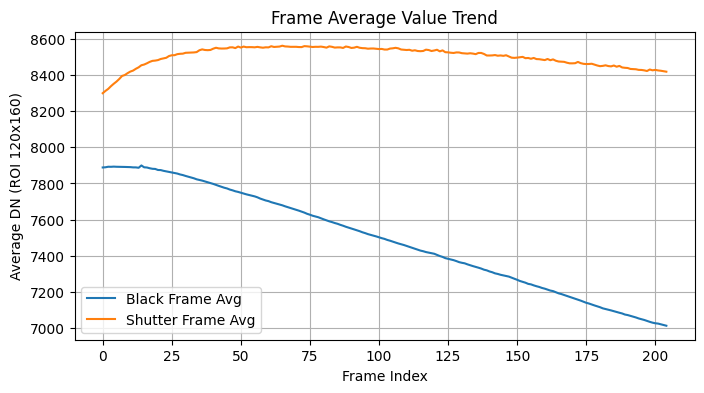

In [76]:
# 数据解析显示脚本

import os
import numpy as np


def split_frames(npy_file, out_dir, height=120, width=162):
    frames = np.load(npy_file)

    if frames.dtype.fields is None:
        raise ValueError("Input npy is not a structured array")

    if "img" not in frames.dtype.fields or "adc" not in frames.dtype.fields:
        raise ValueError("frames must contain 'img' and 'adc' fields")

    os.makedirs(out_dir, exist_ok=True)

    black_imgs = []
    shutter_imgs = []
    adc_list = []

    for frame in frames:
        img = frame["img"][:height, :width]
        adc = int(frame["adc"])

        if adc == 0:
            black_imgs.append(img)
        else:
            shutter_imgs.append(img)
            adc_list.append(adc)   # 只记录有效 ADC

    black_imgs = np.asarray(black_imgs)
    shutter_imgs = np.asarray(shutter_imgs)
    adc_arr = np.asarray(adc_list, dtype=np.int32)

    np.save(os.path.join(out_dir, "black_img.npy"), black_imgs)
    np.save(os.path.join(out_dir, "shutter_img.npy"), shutter_imgs)
    np.save(os.path.join(out_dir, "adc.npy"), adc_arr)

    print("Split finished:")
    print(f"  black frames   : {black_imgs.shape}")
    print(f"  shutter frames : {shutter_imgs.shape}")
    print(f"  adc array      : {adc_arr.shape}")


npy_file = None
out_dir = None

if npy_file is None:
    npy_file = f"{frames_path}"

if out_dir is None:
    out_dir = f"{frames_folder}"

split_frames(npy_file, out_dir)

# =============================
# 输入文件路径
# =============================
black_file   = f"{out_dir}/black_img.npy"
shutter_file = f"{out_dir}/shutter_img.npy"
adc_file     = f"{out_dir}/adc.npy"

black = np.load(black_file)      # (N, 120, 162), u16
shutter = np.load(shutter_file)  # (N, 120, 162), u16
adc = np.load(adc_file)          # (N,), u16

assert black.shape == shutter.shape
assert black.shape[0] == adc.shape[0]

num_frames, height, width = black.shape
assert width >= 2

# =============================
# VTEMP -> FPA 温度
# =============================
# 每行最后两个像素是 VTEMP
vtemp_black = black[:, :, -2:].astype(np.float64)
vtemp_shutter = shutter[:, :, -2:].astype(np.float64)

# 同一帧：black + shutter 的所有 VTEMP 一起平均
vtemp_mean = np.mean(
    np.concatenate([vtemp_black, vtemp_shutter], axis=1),
    axis=(1, 2)
)

# T(FPA) = 25 + (VTEMP - 8192) / 70
temp_fpa_c = 25.0 + (vtemp_mean - 8192.0) / 70.0

temp_adc_c = np.array([adc_to_temp_c(v) for v in adc])

# =============================
# 画图
# =============================
x = np.arange(num_frames)

plt.figure()
plt.plot(x, temp_fpa_c, label="FPA VTEMP")
plt.plot(x, temp_adc_c, label="NTC ADC")
plt.xlabel("Frame Index")
plt.ylabel("Temperature (C)")
plt.legend()
plt.grid(True)
out_png = os.path.join(out_dir, "temperature_curve.png")
plt.savefig(out_png, dpi=150, bbox_inches="tight")

# =============================
# 有效成像区域平均值统计
# 有效区域: [120, 160]，排除最后 2 列 VTEMP
# =============================

def save_frame_avg(data, name, out_dir):
    """
    data: (N, H, W) uint16
    name: 'black' or 'shutter'
    """
    # 有效成像区域
    roi = data[:, :120, :160].astype(np.float64)

    # 每帧平均值
    frame_avg = np.mean(roi, axis=(1, 2))

    # 总平均值
    total_avg = np.mean(frame_avg)

    # 保存 npy
    npy_path = os.path.join(out_dir, f"{name}_avg.npy")
    np.save(npy_path, frame_avg)

    # 保存 txt
    txt_path = os.path.join(out_dir, f"{name}_avg.txt")
    with open(txt_path, "w") as f:
        for i, v in enumerate(frame_avg):
            f.write(f"frame {i:04d}: {v:.3f}\n")
        f.write("\n")
        f.write(f"total_avg: {total_avg:.3f}\n")

    # 打印
    print(f"{name} frame average:")
    print(f"  frames     : {len(frame_avg)}")
    print(f"  mean(min)  : {frame_avg.min():.3f}")
    print(f"  mean(max)  : {frame_avg.max():.3f}")
    print(f"  mean(avg)  : {total_avg:.3f}")
    print(f"  saved to   : {npy_path}, {txt_path}")
    print()

    return frame_avg, total_avg


black_avg, black_total_avg = save_frame_avg(black, "black", out_dir)
shutter_avg, shutter_total_avg = save_frame_avg(shutter, "shutter", out_dir)

x_black = np.arange(len(black_avg))
x_shutter = np.arange(len(shutter_avg))
plt.figure(figsize=(8, 4))

plt.plot(x_black, black_avg, label="Black Frame Avg", linewidth=1.5)
plt.plot(x_shutter, shutter_avg, label="Shutter Frame Avg", linewidth=1.5)

plt.xlabel("Frame Index")
plt.ylabel("Average DN (ROI 120x160)")
plt.title("Frame Average Value Trend")
plt.legend()
plt.grid(True)

out_png = os.path.join(out_dir, "frame_avg_trend.png")
plt.savefig(out_png, dpi=150, bbox_inches="tight")

plt.show()


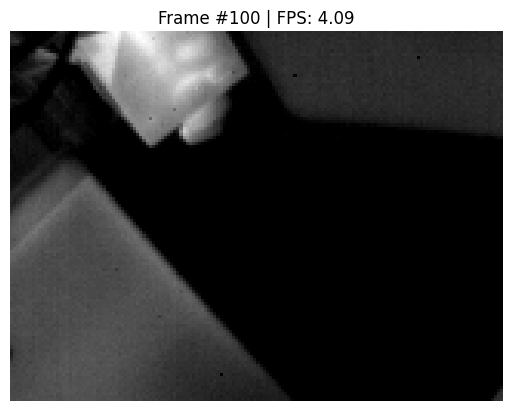

KeyboardInterrupt: 

In [7]:
import serial
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import clear_output
import time

class ImagePacketDecoder:
    """解析固定大小图像包，每包第一个字节为 0xFF，剩余为 u8 像素数据。"""
    def __init__(self, width, height):
        self.width = width
        self.height = height
        self.packet_size = width * height + 1
        self.reset()

    def reset(self):
        self.state = "WAIT_HEADER"
        self.buffer = np.zeros(self.width * self.height, dtype=np.uint8)
        self.addr = 0

    def feed_byte(self, byte):
        if self.state == "WAIT_HEADER":
            if byte == 0xFF:
                self.state = "RECEIVE_DATA"
            return None
        elif self.state == "RECEIVE_DATA":
            self.buffer[self.addr] = byte
            self.addr += 1
            if self.addr >= self.buffer.size:
                img = self.buffer.reshape((self.height, self.width))
                self.reset()
                return img
        return None

def run_uart_with_fps(port="COM8", baud=115200, width=160, height=120):
    decoder = ImagePacketDecoder(width, height)
    
    frame_count = 0
    last_time = time.time()
    
    with serial.Serial(port, baud, timeout=0.01) as ser:
        print("等待圖像幀...")
        
        while True:
            raw = ser.read(1)
            if not raw:
                continue
            
            img = decoder.feed_byte(raw[0])
            if img is not None:
                frame_count += 1
                now = time.time()
                dt = now - last_time
                fps = 1.0 / dt if dt > 0 else 0
                last_time = now
                
                clear_output(wait=True)
                plt.imshow(img, cmap="gray")
                plt.title(f"Frame #{frame_count} | FPS: {fps:.2f}")
                plt.axis('off')
                plt.show()

run_uart_with_fps("COM31", 5000000, 160, 120)